# Análise exploratória
Análise sobre o dataset 911.csv

|**Nome:**|José Diniz Junior            |**RA:**|183134|
|-----|-----------------------------|---|------|
|**Nome:**|Roberto Leonardo Rodrigues   |**RA:**|060235|



In [37]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib
%matplotlib inline

matplotlib.rcParams['font.size'] = 12
matplotlib.rcParams['figure.dpi'] = 150

import seaborn as sns
from IPython.core.pylabtools import figsize
from matplotlib.ticker import FormatStrFormatter

In [38]:
df = pd.read_csv('911.csv', encoding='utf-8', quotechar='"')
df.info()
df

<class 'pandas.DataFrame'>
RangeIndex: 99492 entries, 0 to 99491
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   lat        99492 non-null  float64
 1   lng        99492 non-null  float64
 2   desc       99492 non-null  str    
 3   zip        86637 non-null  float64
 4   title      99492 non-null  str    
 5   timeStamp  99492 non-null  str    
 6   twp        99449 non-null  str    
 7   addr       98973 non-null  str    
 8   e          99492 non-null  int64  
dtypes: float64(3), int64(1), str(5)
memory usage: 21.0 MB


,lat,lng,desc,zip,title,timeStamp,twp,addr,e
0,40.297876,-75.581294,REINDEER CT & DEAD END; NEW HANOVER; Station ...,19525.0,EMS: BACK PAINS/INJURY,2015-12-10 17:40:00,NEW HANOVER,REINDEER CT & DEAD END,1
1,40.258061,-75.264680,BRIAR PATH & WHITEMARSH LN; HATFIELD TOWNSHIP...,19446.0,EMS: DIABETIC EMERGENCY,2015-12-10 17:40:00,HATFIELD TOWNSHIP,BRIAR PATH & WHITEMARSH LN,1
2,40.121182,-75.351975,HAWS AVE; NORRISTOWN; 2015-12-10 @ 14:39:21-St...,19401.0,Fire: GAS-ODOR/LEAK,2015-12-10 17:40:00,NORRISTOWN,HAWS AVE,1
3,40.116153,-75.343513,AIRY ST & SWEDE ST; NORRISTOWN; Station 308A;...,19401.0,EMS: CARDIAC EMERGENCY,2015-12-10 17:40:01,NORRISTOWN,AIRY ST & SWEDE ST,1
4,40.251492,-75.603350,CHERRYWOOD CT & DEAD END; LOWER POTTSGROVE; S...,NaN,EMS: DIZZINESS,2015-12-10 17:40:01,LOWER POTTSGROVE,CHERRYWOOD CT & DEAD END,1
...,...,...,...,...,...,...,...,...,...
99487,40.132869,-75.333515,MARKLEY ST & W LOGAN ST; NORRISTOWN; 2016-08-2...,19401.0,Traffic: VEHICLE ACCIDENT -,2016-08-24 11:06:00,NORRISTOWN,MARKLEY ST & W LOGAN ST,1
99488,40.006974,-75.289080,LANCASTER AVE & RITTENHOUSE PL; LOWER MERION; ...,19003.0,Traffic: VEHICLE ACCIDENT -,2016-08-24 11:07:02,LOWER MERION,LANCASTER AVE & RITTENHOUSE PL,1
99489,40.115429,-75.334679,CHESTNUT ST & WALNUT ST; NORRISTOWN; Station ...,19401.0,EMS: FALL VICTIM,2016-08-24 11:12:00,NORRISTOWN,CHESTNUT ST & WALNUT ST,1
99490,40.186431,-75.192555,WELSH RD & WEBSTER LN; HORSHAM; Station 352; ...,19002.0,EMS: NAUSEA/VOMITING,2016-08-24 11:17:01,HORSHAM,WELSH RD & WEBSTER LN,1


A coluna title foi dividida em 'service' e 'subService'

In [39]:
df['service'] = [words.split(sep=':')[0] for words in np.array(df.loc[:,'title'])]
df['subService'] = [words.split(sep=':')[1] for words in np.array(df.loc[:,'title'])]

In [40]:
df.service.value_counts()

service
EMS        48877
Traffic    35695
Fire       14920
Name: count, dtype: int64

In [44]:
df.groupby(by='service').subService

service  subService                 
EMS      RESPIRATORY EMERGENCY          5112
         CARDIAC EMERGENCY              5012
         FALL VICTIM                    4863
         VEHICLE ACCIDENT               3935
         SUBJECT IN PAIN                2687
                                        ... 
Traffic  ROAD OBSTRUCTION -             3144
         HAZARDOUS ROAD CONDITIONS -    1086
         VEHICLE FIRE -                  553
         VEHICLE LEAKING FUEL -           77
         DEBRIS/FLUIDS ON HIGHWAY -       67
Name: count, Length: 110, dtype: int64

Convertendo campo 'timeStamp' para datetime e gerando novas colunas como 'hour', 'month' e 'dayOfWeek'

In [6]:
df.timeStamp = pd.to_datetime(df.timeStamp);df['hour'] = df.timeStamp.dt.hour;
df['month'] = df.timeStamp.dt.month;df['dayOfWeek'] = df.timeStamp.dt.dayofweek;
print('Dados entre ' + str(df.timeStamp.dt.date.min()) + ' a ' + str(df.timeStamp.dt.date.max()))

Dados entre 2015-12-10 a 2016-08-24


In [7]:
df[df['service']=='EMS'].groupby(['month','subService']).size().reset_index(name='total')

,month,subService,total
0,1,ABDOMINAL PAINS,186
1,1,ALLERGIC REACTION,45
2,1,ALTERED MENTAL STATUS,160
3,1,AMPUTATION,4
4,1,ANIMAL BITE,8
...,...,...,...
478,12,UNKNOWN MEDICAL EMERGENCY,143
479,12,UNRESPONSIVE SUBJECT,91
480,12,VEHICLE ACCIDENT,361
481,12,VEHICLE FIRE,3


In [8]:
ttt = df[df['service']=='EMS'].groupby(['month']).size()
ttt.sort_values()

month
12    3898
8     4508
2     5413
4     5680
6     5720
5     5734
3     5832
7     6029
1     6063
dtype: int64

In [9]:
df.groupby(['hour']).size()

hour
0     2112
1     1721
2     1549
3     1435
4     1418
5     1629
6     2513
7     3970
8     5044
9     5314
10    5413
11    5543
12    6029
13    5967
14    5997
15    6154
16    6490
17    6517
18    5762
19    4908
20    4377
21    3788
22    3283
23    2559
dtype: int64

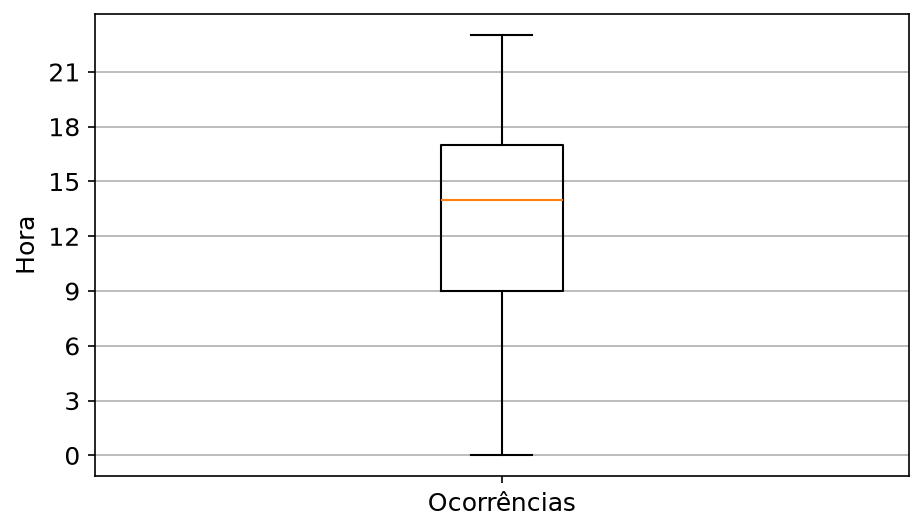

In [10]:
#plt.figsize(7,4);plt.boxplot(df['hour'],labels=['Ocorrências']);plt.ylabel('Hora')
#plt.yticks(np.arange(0, 24, step=3));plt.grid(axis='y');plt.show()

plt.figure(figsize=(7, 4))

plt.boxplot(df['hour'], tick_labels=['Ocorrências'])
plt.ylabel('Hora')
plt.yticks(np.arange(0, 24, step=3))
plt.grid(axis='y')
plt.show()

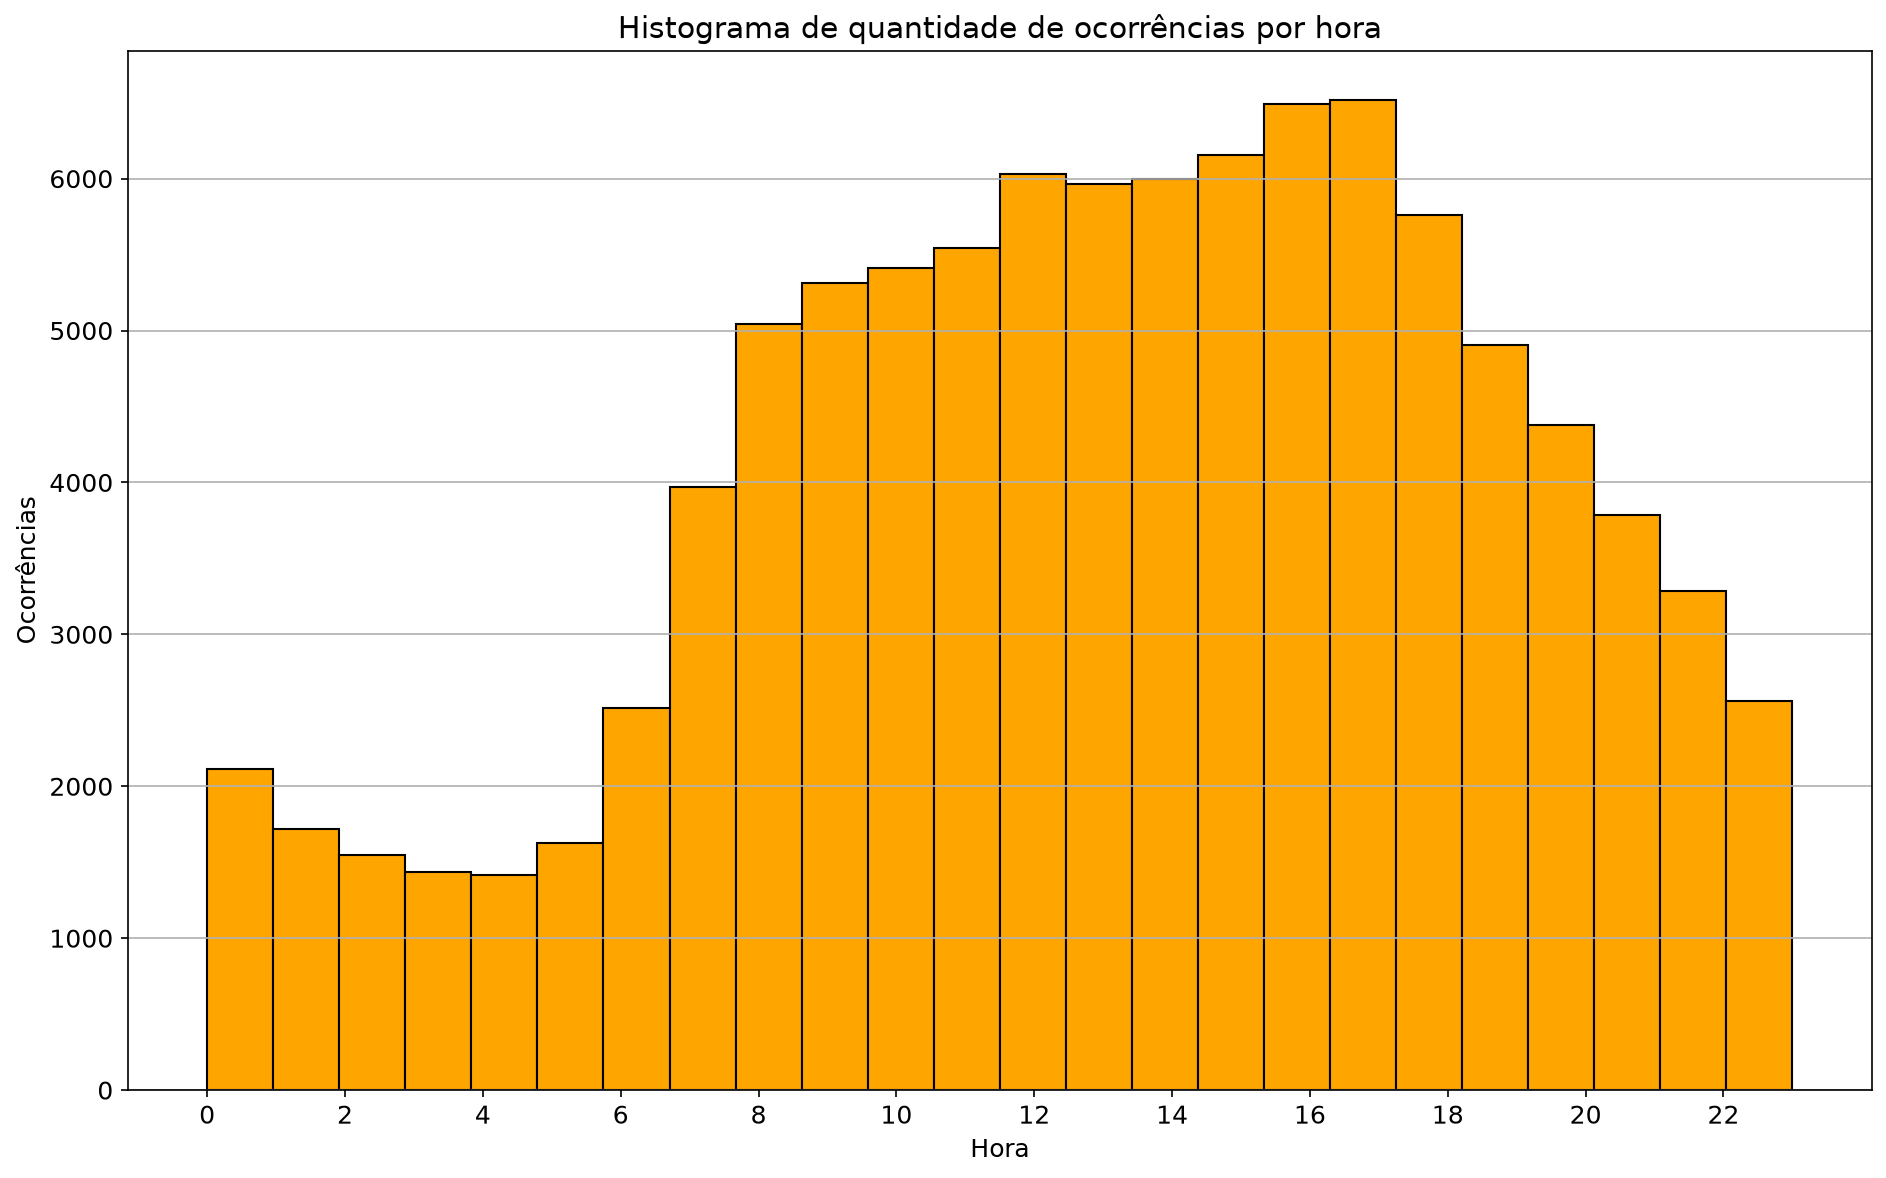

In [11]:
figsize(15,9)
plt.hist(df.hour, color = 'orange', edgecolor = 'black',
         bins = int(195/8))

plt.title('Histograma de quantidade de ocorrências por hora')
plt.xlabel('Hora'); 
plt.ylabel('Ocorrências');
plt.xticks(np.arange(0, 24, step=2))
plt.grid(axis='y')

In [12]:
services = df.groupby('service')['service'].count().sort_values(ascending=False).index[:]
services

Index(['EMS', 'Traffic', 'Fire'], dtype='str', name='service')

In [13]:
figsize(7, 3)

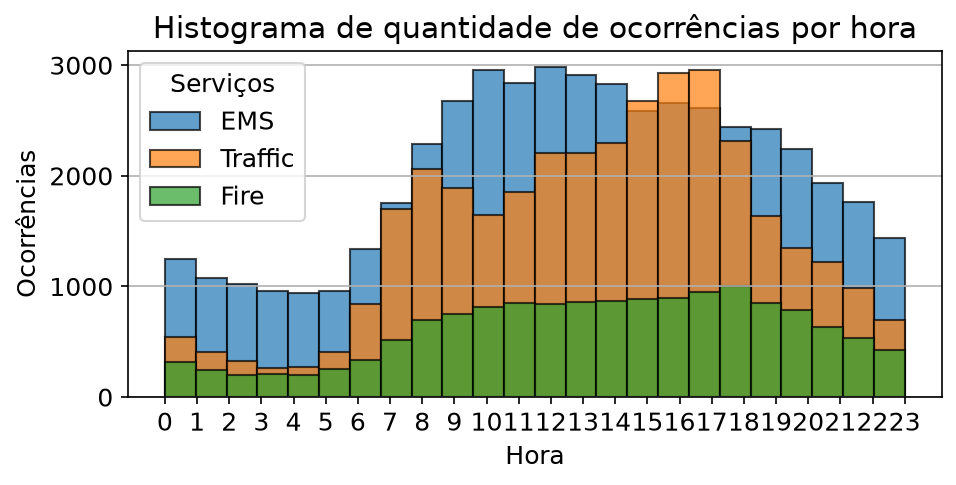

In [14]:
for srv in services:
    subset = df[df['service'] == srv];
    plt.hist(subset['hour'], 
             edgecolor = 'black',
             alpha=0.7,bins = int(195/8), 
             label = srv)
plt.legend(prop={'size': 12}, 
           title = 'Serviços');
plt.title('Histograma de quantidade de ocorrências por hora');
plt.xlabel('Hora'); plt.ylabel('Ocorrências');
plt.xticks(np.arange(0, 24, step=1));
plt.grid(axis='y')

In [15]:
totalService = df.groupby('month')['service'].count().sort_index(ascending=False)
totalEMS = df[df['service']=='EMS'].groupby('month')['service'].count().sort_index(ascending=False)
totalTrafic = df[df['service']=='Traffic'].groupby('month')['service'].count().sort_index(ascending=False)
totalFire = df[df['service']=='Fire'].groupby('month')['service'].count().sort_index(ascending=False)
figsize(7,4)

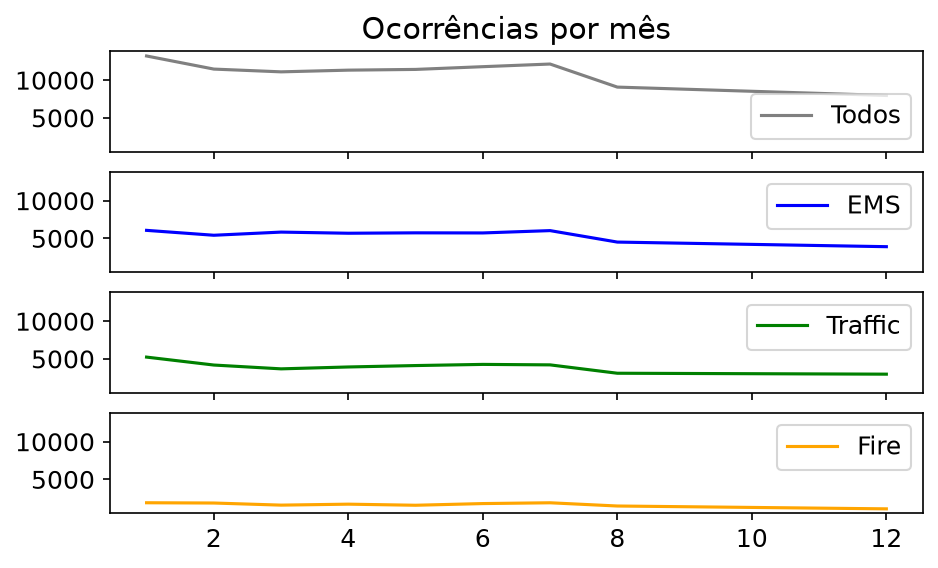

In [16]:
f, (ax0, ax1, ax2, ax3) = plt.subplots(4, sharex=True, sharey=True);ax0.set_title('Ocorrências por mês');ax0.plot(totalService , color='gray');ax0.legend(('Todos',),loc='lower right', prop={'size': 12});ax1.plot(totalEMS , color='blue');ax1.legend(('EMS',),loc='upper right', prop={'size': 12});ax2.plot(totalTrafic, color='green', label='Traffic');ax2.legend(('Traffic',), loc='upper right', prop={'size': 12});ax3.plot(totalFire, color='orange');ax3.legend(('Fire',), loc='upper right', prop={'size': 12});plt.setp([a.get_xticklabels() for a in f.axes[:-1]], visible=False)

In [17]:
all = [totalService,totalEMS,totalTrafic,totalFire]

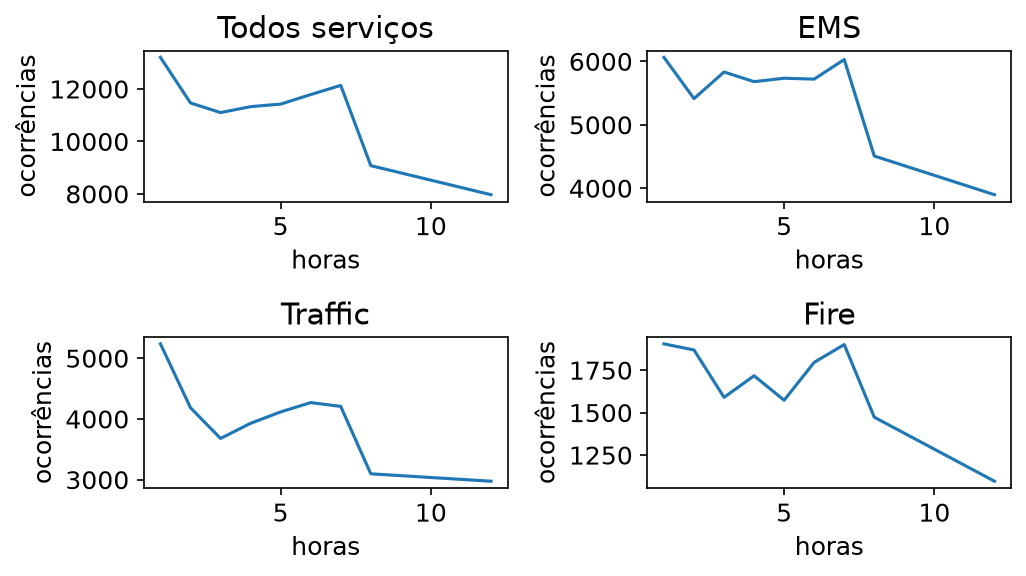

In [18]:
names = ['Todos serviços', 'EMS', 'Traffic', 'Fire']

figs, axes = plt.subplots(nrows=2,ncols=2)
idx = 0
for ir, row in enumerate(axes):
    for ic, col in enumerate(row):
        col.plot(all[idx])
        col.set_title(names[idx])  
        col.set_xlabel('horas')
        col.set_ylabel('ocorrências')
        idx+=1
                
figs.tight_layout()            
plt.show()

In [35]:
coordenadaOcr = pd.DataFrame(
    df.groupby(['lat','lng'])
    .e.value_counts().nlargest(100)
    .sort_values(ascending=True)
    .reset_index(name='total'))
coordenadaOcr

,lat,lng,e,total
0,40.254100,-75.338864,1,90
1,40.106839,-75.123804,1,90
2,40.200770,-75.346051,1,91
3,40.161470,-75.130159,1,92
4,40.004556,-75.284357,1,93
...,...,...,...,...
95,40.172314,-75.492728,1,521
96,40.024967,-75.282905,1,905
97,40.133037,-75.408463,1,938
98,40.229008,-75.387852,1,1006


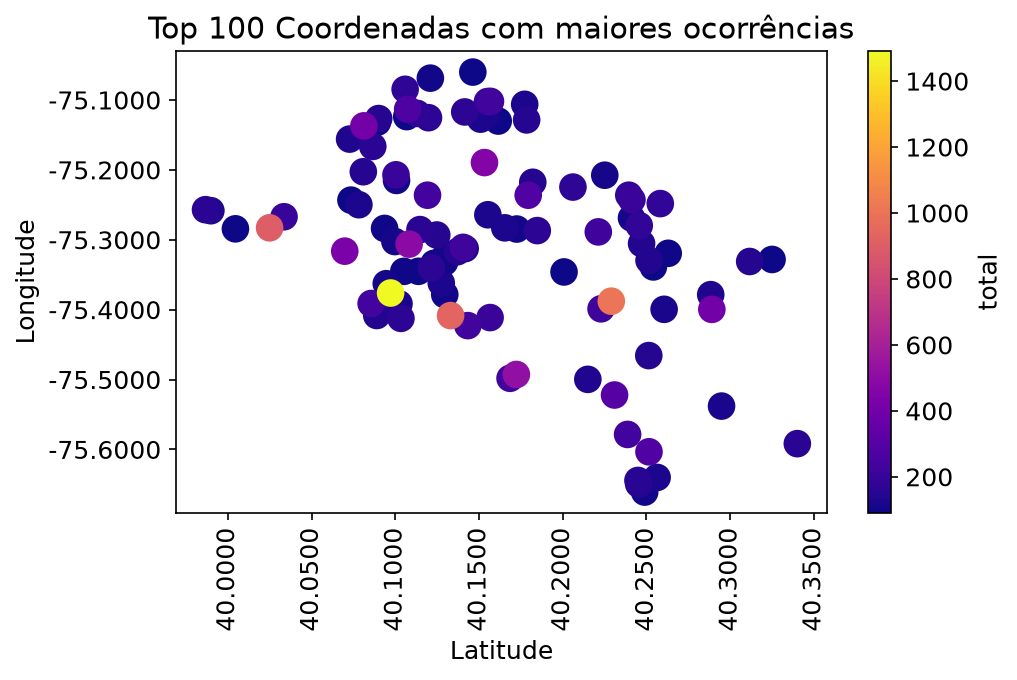

In [36]:
figsize(7,4); 
fig, ax = plt.subplots(); 
ax.yaxis.set_major_formatter(FormatStrFormatter('%.4f'));
ax.xaxis.set_major_formatter(FormatStrFormatter('%.4f'));
coordenadaOcr.plot(kind="scatter", x='lat', y='lng', c='total', s=150, cmap="plasma", ax=ax,rot=90);
plt.xlabel('Latitude');
plt.ylabel('Longitude');
plt.title('Top 100 Coordenadas com maiores ocorrências');
plt.show()

In [21]:
topTwp = df.groupby('twp').size().sort_values(ascending=False).nlargest(5)

In [22]:
data = topTwp.reset_index(name='total');
sizes = list(data.total);
labels = list(data.twp)
def absValue(val):
    a  = np.round(val/100.*data.total.sum(), 0)
    return a

C:\Users\Diniz\AppData\Local\Temp\ipykernel_16468\3710422188.py:1: MatplotlibDeprecationWarning: Passing the explode parameter of pie() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  figsize(4,4);explode = (0.05, 0, 0, 0,0);fig1, ax1 = plt.subplots();ax1.pie(sizes,explode, labels=labels, autopct=absValue, shadow=False,pctdistance=0.6, startangle=90)


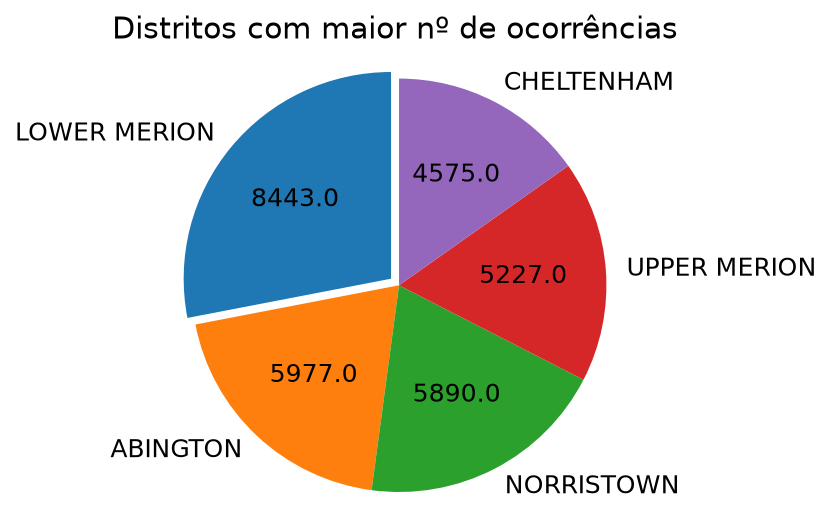

In [23]:
figsize(4,4);explode = (0.05, 0, 0, 0,0);fig1, ax1 = plt.subplots();ax1.pie(sizes,explode, labels=labels, autopct=absValue, shadow=False,pctdistance=0.6, startangle=90)
ax1.axis('equal');plt.title('Distritos com maior nº de ocorrências');plt.show()

In [24]:
fiveEMS = pd.DataFrame(df[df['service']=='EMS'].groupby('subService').size().nlargest(5).reset_index(name='total'))
fiveFire = pd.DataFrame(df[df['service']=='Fire'].groupby('subService').size().nlargest(5).reset_index(name='total'))
fiveTraffic = pd.DataFrame(df[df['service']=='Traffic'].groupby('subService').size().nlargest(5).reset_index(name='total'))